# 04 — Classification and evaluation (Figures 4–5; Tables 2, 4–5)

**Tujuan.** Hitung ulang confusion matrix paper dengan orientasi yang benar; tampilkan hasil kampanye hanya jika JSON final-test dan fingerprint tersedia. Figure 4–5 paper memakai **predicted rows / true columns**. Kode memakai **true rows / predicted columns**. Semua visual di bawah berlabel `PAPER_REFERENCE`, bukan prediksi kita.

In [1]:
from pathlib import Path
import os, sys
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "reproduction/cadvit/model.py").is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
ARTIFACT_ROOT = Path(os.environ["CAD_VIT_ARTIFACT_ROOT"]).expanduser().resolve() if os.environ.get("CAD_VIT_ARTIFACT_ROOT") else None
print("Artifact root:", ARTIFACT_ROOT if ARTIFACT_ROOT else "PENDING (set CAD_VIT_ARTIFACT_ROOT)")

Artifact root: PENDING (set CAD_VIT_ARTIFACT_ROOT)


PAPER_REFERENCE Figure 4, p. 91510 N 367 accuracy 0.9918256130790191
Per-class: {'No DR': {'support': 181, 'precision': 0.9836956521739131, 'recall': 1.0, 'specificity': 0.9838709677419355, 'f1': 0.9917808219178083, 'one_vs_rest_accuracy': 0.9918256130790191}, 'DR': {'support': 186, 'precision': 1.0, 'recall': 0.9838709677419355, 'specificity': 1.0, 'f1': 0.991869918699187, 'one_vs_rest_accuracy': 0.9918256130790191}}


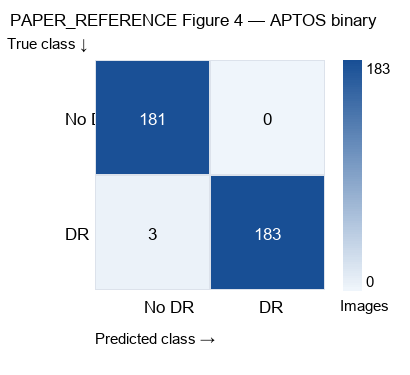

In [2]:
from reproduction.cadvit.visualization import paper_binary_reference, paper_five_reference, confusion_png
binary = paper_binary_reference()
print(binary["source"], "N", binary["metrics"]["n"], "accuracy", binary["metrics"]["accuracy"])
print("Per-class:", binary["metrics"]["per_class"])
confusion_png(binary["metrics"], binary["class_names"], "PAPER_REFERENCE Figure 4 — APTOS binary")

PAPER_REFERENCE Figure 5, p. 91511 (APTOS2019) N 367 accuracy 0.885558583106267 weighted F1 0.8842215882589627 macro F1 0.7806526957217652


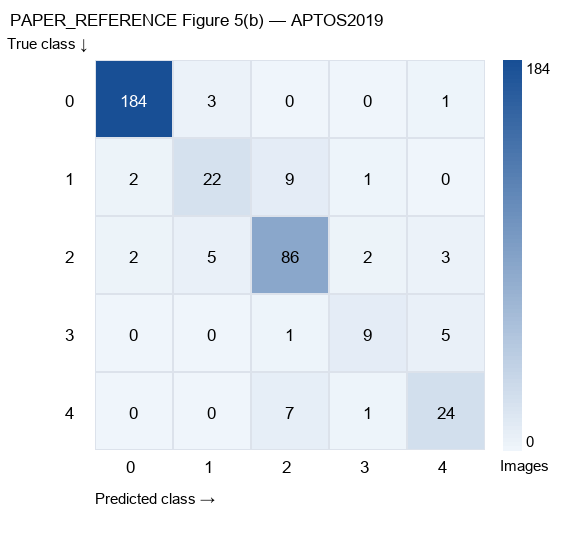

In [3]:
aptos_paper = paper_five_reference("APTOS2019")
m = aptos_paper["metrics"]
print(aptos_paper["source"], "N", m["n"], "accuracy", m["accuracy"], "weighted F1", m["f1_weighted"], "macro F1", m["f1_macro"])
confusion_png(m, aptos_paper["class_names"], "PAPER_REFERENCE Figure 5(b) — APTOS2019")

PAPER_REFERENCE Figure 5, p. 91511 (DDR) N 1253 accuracy 0.8483639265762171 weighted F1 0.8443922537120716 macro F1 0.7025451257055899


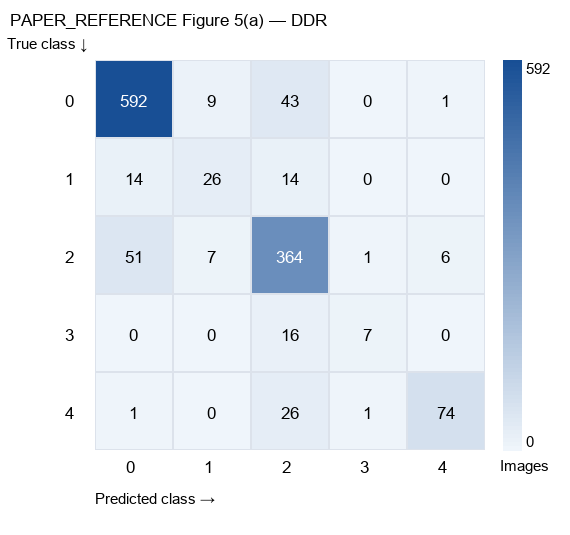

In [4]:
ddr_paper = paper_five_reference("DDR")
m = ddr_paper["metrics"]
print(ddr_paper["source"], "N", m["n"], "accuracy", m["accuracy"], "weighted F1", m["f1_weighted"], "macro F1", m["f1_macro"])
confusion_png(m, ddr_paper["class_names"], "PAPER_REFERENCE Figure 5(a) — DDR")

In [5]:
from reproduction.cadvit.visualization import load_controlled_result
from IPython.display import display
if ARTIFACT_ROOT:
    for name in ("aptos_r16", "ddr_full"):
        item = load_controlled_result(ARTIFACT_ROOT, "balanced_v1", name)
        print(name, item["status"], item.get("reason", "fingerprint verified"))
        if item["status"] == "AVAILABLE":
            metrics = item["result"]["metrics"]
            print("CONTROLLED_FINAL_TEST", "campaign", "balanced_v1", "run", name,
                  "split", item["result"]["split"], "result SHA-256", item["result_sha256"],
                  "manifest SHA-256", item["result"]["manifest_sha256"],
                  "selected epoch", item["result"]["selected_epoch"])
            print("accuracy", metrics["accuracy"], "macro-F1", metrics["f1_macro"],
                  "weighted-F1", metrics["f1_weighted"], "micro-F1", metrics["f1_micro"])
            display(confusion_png(metrics, [str(i) for i in range(5)],
                                  f"BALANCED_V1 Final Test — {item['result']['dataset']}"))
else:
    print("PENDING BALANCED_V1 final test; no inference is run by this notebook")

PENDING BALANCED_V1 final test; no inference is run by this notebook


**Interpretasi.** Figure 5 mengindikasikan support-weighted precision/recall/F1 pada Tabel 4–5; specificity DDR masih berbeda 0,1 poin setelah pembulatan. Figure 4 Tabel 2 memakai label 'Accuracy' per kategori yang cocok dengan precision, bukan one-vs-rest accuracy. Hasil historis V2 tidak dicampur dengan kampanye baru. Macro-F1 dan weighted-F1 selalu disebut dengan namanya.